# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [3]:
DTYPES_clients = {
    "client_id": "string", 
    "birth_date": "string", 
    "gender": "category",
    "city": "string", 
    "segment": "category",
    "loyalty_tier": "category",
    "card_type": "category",
    "registration_date": "string", 
    "card_open_date": "string", 
    "income_source": "string",
    "monthly_income": "float64", 
    "has_mobile_app": "category",
    "app_last_login": "string", 
    "satisfaction_score": "category", 
    "branch_code": "string",
    "marketing_opt_in": "category"
}

clients = pd.read_csv(
    RAW_CLIENTS,
    dtype=DTYPES_clients,
    encoding="utf-8-sig",
)

DTYPES_transactions = {
    "txn_id": "string", 
    "client_id": "string", 
    "txn_datetime": "string",
    "amount": "float64", 
    "currency": "string",
    "category": "string",
    "mcc_code": "string",
    "channel": "category", 
    "status": "category"
}

transactions = pd.read_csv(
    RAW_TXN,
    dtype=DTYPES_transactions,
    delimiter=';',
    encoding="cp1251",
    decimal=','
)

## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [4]:
print(f'Количество записей в таблице с клиентами {len(clients)}')
overview = pd.DataFrame({
    'dtype': clients.dtypes.astype(str),
    'n_unique': clients.nunique(),
    'n_missing': clients.isna().sum(),
    'missing_%': (clients.isna().mean() * 100).round(2),
    'example': clients.iloc[5],
})
print(overview)
print('\n\n')

print(f'Количество записей в таблице с транзакциями {len(transactions)}')
overview = pd.DataFrame({
    'dtype': transactions.dtypes.astype(str),
    'n_unique': transactions.nunique(),
    'n_missing': transactions.isna().sum(),
    'missing_%': (transactions.isna().mean() * 100).round(2),
    'example': transactions.iloc[5],
})
print(overview)

Количество записей в таблице с клиентами 5674
                       dtype  n_unique  n_missing  missing_%                 example
client_id             string      5619          0       0.00                 C003674
birth_date            string      4807          0       0.00              1983-11-23
gender              category         2          0       0.00                       Ж
city                  string        17          0       0.00                  Москва
segment             category         4          0       0.00              Зарплатный
loyalty_tier        category         4          0       0.00                 Базовый
card_type           category         3          0       0.00               Кредитная
registration_date     string      3248          0       0.00              30.04.2017
card_open_date        string      2633          0       0.00              24.08.2019
income_source         string         3          0       0.00  Зарплата в нашем банке
monthly_income     

In [5]:
print(f"Количество человек с ежемесячным доходом < 0 : {len(clients[clients['monthly_income']<0])}")
clients[clients['monthly_income']<0].head(5)

Количество человек с ежемесячным доходом < 0 : 41


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
21,C001227,1992-05-07,М,Санкт Петербург,Массовый,Базовый,Дебетовая,17.02.2020,27.11.2022,Не указан,-999.0,Да,2024-06,NaN,00499,Да
119,C001272,1973-07-25,Ж,Казань,Массовый,Серебро,Дебетовая,07.02.2020,13.08.2021,Зарплата в нашем банке,-999.0,Да,2024-08,3,00214,Да
256,C001315,1978-10-11,М,ЕКАТЕРИНБУРГ,Премиальный,Золото,Дебетовая,27.01.2022,30.10.2024,Зарплата в другом банке,-999.0,Нет,<NA>,4,00900,Да
303,C001778,1978-05-01,Ж,Москва,Премиальный,Золото,Премиальная,17.03.2019,02.11.2019,Зарплата в нашем банке,-999.0,Да,2025-05,NaN,00178,Да
342,C000859,1936-10-07,М,Москва,Массовый,Серебро,Кредитная,19.07.2016,26.06.2021,Зарплата в другом банке,-999.0,Нет,<NA>,5,00883,Да


In [6]:
print(f"Количество транзакций < 0 : {len(transactions[transactions['amount']<0])}")
print(transactions[transactions['amount']<0].head(5))
print(transactions[transactions['amount']<0]['status'].unique())

Количество транзакций < 0 : 7343
     txn_id client_id         txn_datetime   amount currency          category mcc_code      channel   status
184  100174   C005372  2024-01-01 11:31:08  -905.31      RUB  Связь и интернет     4814        Карта  возврат
193  100183   C005202  2024-01-01 11:42:15  -393.20      RUB            Аптеки     5912          СБП  возврат
401  100390   C004093           2024-01-01 -1767.92      RUB  кафе и рестораны     5812        Карта  возврат
426  100415   C004169  2024-01-01 15:22:19 -1283.95      RUB          Продукты     5411  Онлайн-банк  возврат
520  100508   C001052  2024-01-01 16:51:08  -442.25      RUB         Транспорт     4111        Карта  возврат
['возврат']
Categories (3, object): ['возврат', 'отклонено', 'успешно']


In [7]:
transactions[transactions['amount']<0]['status'].unique()

['возврат']
Categories (3, object): ['возврат', 'отклонено', 'успешно']

In [8]:
print(f"Количество строк, где указано, что клиент установил приложение, но с пропусками в месяце последнего входа: {len(clients[(clients['app_last_login'].isna()) & (clients['has_mobile_app']=='Да')])}")

Количество строк, где указано, что клиент установил приложение, но с пропусками в месяце последнего входа: 0


In [10]:
print('Анализ на, то есть ли города в таблице с данными о клиентах, которые имеют разное написание:')
", ".join(clients['city'].unique())

Анализ на, то есть ли города в таблице с данными о клиентах, которые имеют разное написание:


'Нижний Новгород,  москва, Санкт-Петербург, казань, Казань, Москва, г. Санкт-Петербург, г.Екатеринбург, Санкт Петербург, МОСКВА, г. Москва, Н. Новгород, СПб, г. Новосибирск, Екатеринбург, Новосибирск, ЕКАТЕРИНБУРГ'

In [11]:
print('Анализ на, то есть ли категории в таблице с данными о транзакциях, которые имеют разное написание:')
", ".join(transactions['category'].unique())

Анализ на, то есть ли категории в таблице с данными о транзакциях, которые имеют разное написание:


'Продукты, АЗС, Кафе и рестораны, Одежда и обувь, Транспорт, Развлечения и досуг, Онлайн-сервисы, Кафе/рестораны, Связь и интернет, Аптеки, Связь и Интернет, кафе и рестораны'

### 2.2. Дубли

In [12]:
print('Полных дубликатов строк в клиентах:', clients.duplicated().sum())
print('Полных дубликатов строк в транзакциях:', transactions.duplicated().sum())

Полных дубликатов строк в клиентах: 40
Полных дубликатов строк в транзакциях: 1257


### 2.3. Соответствие данных описанию полей из задания

Предполагается, что код типа торговой точки, соответствует категории

In [13]:
pd.crosstab(transactions['category'].str.lower().str.replace('кафе/рестораны','кафе и рестораны'), transactions['mcc_code'])

mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
азс,23,19,15,56773,17,17,16,19,22
аптеки,17,19,18,12,18,20,19,44693,14
кафе и рестораны,24,25,22,26,28,79013,29,33,21
одежда и обувь,20,21,23,23,63049,17,19,20,17
онлайн-сервисы,11,14,9,26,12,14,42500,9,15
продукты,60,44,162453,48,54,67,71,52,58
развлечения и досуг,14,19,11,25,15,14,20,12,46236
связь и интернет,17,47892,23,16,19,10,18,15,16
транспорт,70659,23,22,15,17,32,27,22,28


### 2.4. Связь между таблицами

Связь таблиц осуществляется через столбец client_id

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

#### Результаты аудита данных

По итогам аудита выявлены следующие особенности:

- **Полные дубликаты:** 40 строк в таблице `clients` и 1 257 строк в `transactions`. Требуют удаления, поскольку могут приводить к искажению результатов анализа.

- **Пропущенные значения в `clients`:**
  - `monthly_income` — 559 пропусков, причина отсутствия данных неизвестна.
  - `app_last_login` — 2 215 пропусков, соответствуют клиентам, не устанавливавшим приложение.
  - `satisfaction_score` — 3 478 пропусков, связаны с тем, что клиенты не проходили опрос.

- **Несогласованность категориальных признаков:** в таблице `clients` обнаружены разные варианты написания одних и тех же городов, в `transactions` — разные названия одинаковых категорий операций.

- **Несоответствие MCC-кодов категориям:** предполагаемая зависимость между MCC-кодом и категорией операции соблюдается не во всех случаях.

- **Отрицательные значения:**
  - `amount` в `transactions` — 7 343 значения, соответствуют возвратам денежных средств и являются допустимыми.
  - `monthly_income` в `clients` — 41 значение `-999`, вероятно, используется как специальный код для обозначения отсутствующих данных о доходе и требует преобразования в пропуски.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [14]:
clients['city'] = clients['city'].str.title().str.replace('Г. ','').str.replace('Г.','').str.replace(' Москва','Москва').str.replace('Санкт Петербург','Санкт-Петербург').str.replace('Спб','Санкт-Петербург').str.replace('Н. Новгород','Нижний Новгород')
clients['registration_date'] = pd.to_datetime(clients['registration_date'],format='%d.%m.%Y')
clients['card_open_date'] = pd.to_datetime(clients['card_open_date'],format='%d.%m.%Y')
clients['birth_date'] = pd.to_datetime(clients['birth_date'],format='%Y-%m-%d')
clients.drop_duplicates(inplace=True)

In [15]:
transactions['txn_datetime'] = pd.to_datetime(transactions['txn_datetime'], format='mixed').dt.normalize()

### 3.2. Категориальные признаки

In [16]:
transactions['category'] = transactions['category'].str.lower().str.replace('кафе/рестораны','кафе и рестораны')

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

### Пропуски есть только в таблице с клиентами

In [17]:
overview = pd.DataFrame({
    'n_missing': clients.isna().sum(),
    'missing_%': (clients.isna().mean() * 100).round(2)
})
print(overview)

                    n_missing  missing_%
client_id                   0       0.00
birth_date                  0       0.00
gender                      0       0.00
city                        0       0.00
segment                     0       0.00
loyalty_tier                0       0.00
card_type                   0       0.00
registration_date           0       0.00
card_open_date              0       0.00
income_source               0       0.00
monthly_income            551       9.78
has_mobile_app              0       0.00
app_last_login           2198      39.01
satisfaction_score       3453      61.29
branch_code                 0       0.00
marketing_opt_in            0       0.00


В поле satisfaction_score 61.3% значений не заполнено, и заполнение средним может в будущем ввести в заблуждение при выдвижении гипотез, поэтому наполним "Unknown"

In [18]:
clients["satisfaction_score"] = clients["satisfaction_score"].cat.add_categories("Unknown")
clients["satisfaction_score"] = clients["satisfaction_score"].fillna("Unknown")

В поле app_last_login отсутствуют значения последнего входа в приложение, так как у людей не установлено приложение, поэтому заполним ""

In [19]:
clients["app_last_login"] = clients["app_last_login"].fillna("")

Есть 41 клиент, у которого в поле заработка отрицательное значение, допустим, что это ошибка в данных и заполним пропусками и дальше обработаем их с ними

In [20]:
clients['monthly_income'] = clients['monthly_income'].replace(-999.0, np.nan)

Для заполнения пропусков посмотрим разницу в доходе в разных сегментах

C:\Users\user\AppData\Local\Temp\ipykernel_19348\337515095.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


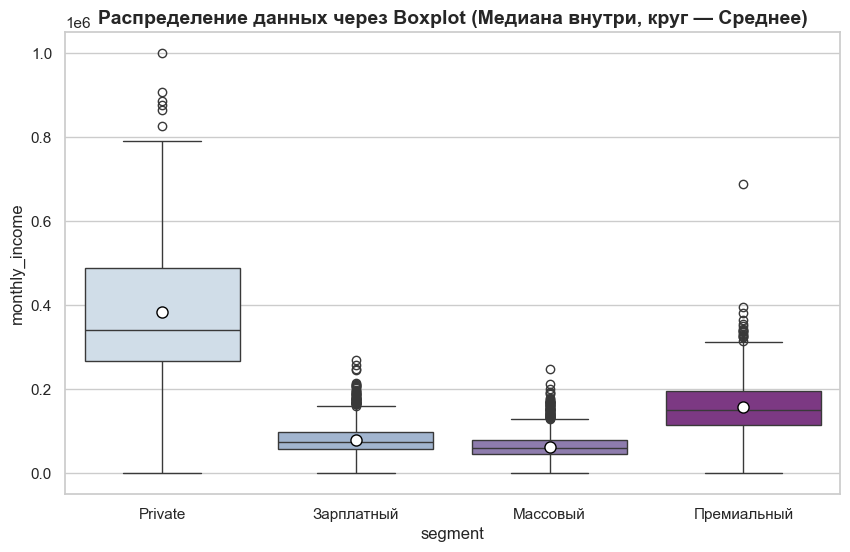

In [21]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.boxplot(
    data=clients, 
    x='segment', 
    y='monthly_income', 
    showmeans=True, 
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"},
    palette='BuPu'
)

plt.title('Распределение данных через Boxplot (Медиана внутри, круг — Среднее)', fontsize=14, fontweight='bold')
plt.show()


Так как средний доход сильно отличается для сегментов, то возьмем медиану для каждого сегмента и этим значением заполним пропуски

In [22]:
clients['monthly_income'] = clients['monthly_income'].fillna(clients.groupby('segment')['monthly_income'].transform('median').round(1))

C:\Users\user\AppData\Local\Temp\ipykernel_19348\2379317079.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clients['monthly_income'] = clients['monthly_income'].fillna(clients.groupby('segment')['monthly_income'].transform('median').round(1))


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [23]:
def iqr_bounds(ser: pd.Series, coef: float = 1.5):
    q1, q3 = ser.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - coef * iqr, q3 + coef * iqr


def iqr_report(data: pd.DataFrame, cols, coef: float = 1.5):
    rows = []
    for col in cols:
        low, up = iqr_bounds(data[col], coef)
        is_low_out = (data[col] < low)
        is_up_out = (data[col] > up)
        outlier_count = is_low_out.sum() + is_up_out.sum()
        outlier_fraction = outlier_count / data[col].shape[0]
        rows.append({
            'столбец': col,
            'нижняя_граница': low,
            'верхняя_граница': up,
            'кол-во_выбросов за нижнюю границу': is_low_out.sum(),
            'кол-во_выбросов за верхнюю границу': is_up_out.sum(),
            'общее кол-во_выбросов': outlier_count,
            'общая доля_выбросов_%': outlier_fraction * 100,
        })
    return pd.DataFrame(rows).set_index('столбец').round(2)


iqr_report(clients, ['monthly_income'])


,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
столбец,,,,,,
monthly_income,-23312.5,184987.5,0,467,467,8.29


In [24]:
iqr_report(transactions, ['amount'])

,нижняя_граница,верхняя_граница,кол-во_выбросов за нижнюю границу,кол-во_выбросов за верхнюю границу,общее кол-во_выбросов,общая доля_выбросов_%
столбец,,,,,,
amount,-2190.31,4849.55,1865,50062,51927,8.44


### В таблице с клиентами есть дубли по идентификатору, которые не удалось как-то объединить, поэтому я их удалила

In [25]:
duplicates_df = clients[clients.duplicated(subset=['client_id'], keep=False)]
clients = clients[~clients['client_id'].isin(duplicates_df['client_id'].unique())]
transactions.drop_duplicates(inplace=True)

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [26]:
print("Всего транзакций : " + str(len(transactions)))

Всего транзакций : 613435


In [27]:
transactions = transactions[(transactions['txn_datetime']>= '2024-01-01') & (transactions['txn_datetime']<= '2025-06-30')]
print("Всего транзакций после фильтра по дате: " + str(len(transactions)))

Всего транзакций после фильтра по дате: 613350


In [28]:
transactions = transactions[transactions['status']== 'успешно']
print("Всего транзакций после фильтра по статусу: " + str(len(transactions)))

Всего транзакций после фильтра по статусу: 593927


In [29]:
df_clean = pd.merge(clients, transactions, on='client_id').reset_index(drop=True)

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [30]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

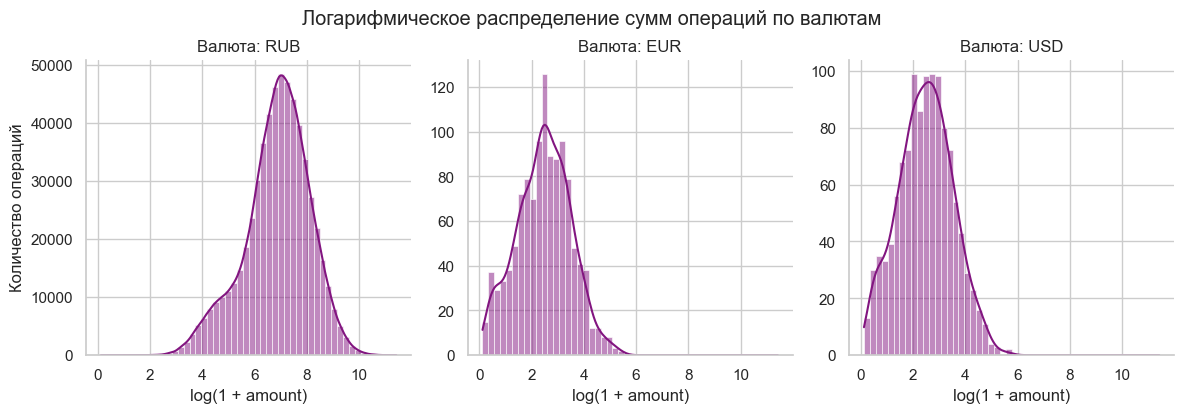

In [31]:
transactions_positive = transactions.copy()

transactions_positive['log_amount'] = np.log1p(
    transactions_positive['amount']
)

g = sns.displot(
    data=transactions_positive,
    x='log_amount',
    col='currency',
    col_wrap=3,
    bins=50,
    kde=True,
    height=4,
    facet_kws={'sharex': False, 'sharey': False},
    color=sns.color_palette("BuPu")[5]
)

g.set_axis_labels('log(1 + amount)', 'Количество операций')
g.set_titles('Валюта: {col_name}')

g.figure.suptitle(
    'Логарифмическое распределение сумм операций по валютам',
    y=1.03
)

plt.show()

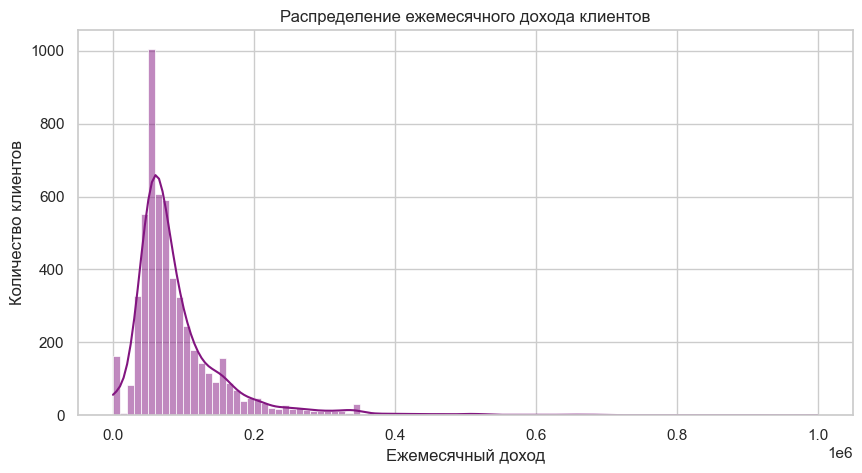

In [32]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=clients,
    x='monthly_income',
    bins=100,
    kde=True,
    color=sns.color_palette("BuPu")[5]
)

plt.title('Распределение ежемесячного дохода клиентов')
plt.xlabel('Ежемесячный доход')
plt.ylabel('Количество клиентов')
plt.show()

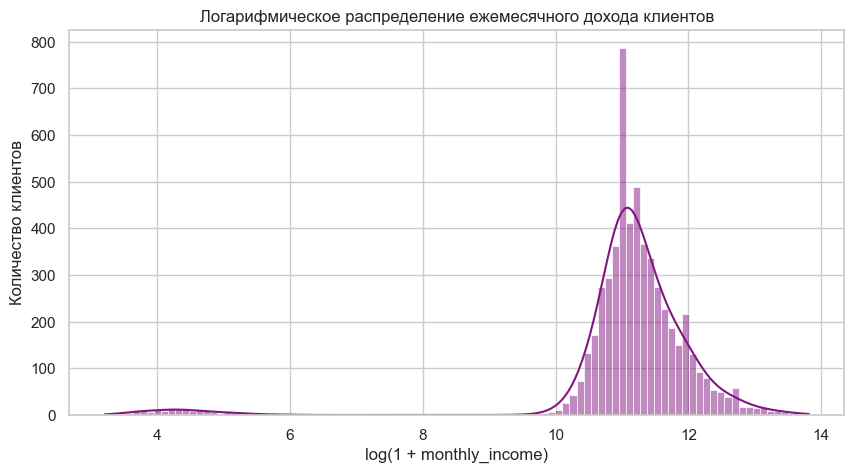

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(clients['monthly_income']),
    bins=100,
    kde=True,
    color=sns.color_palette("BuPu")[5]
)

plt.title('Логарифмическое распределение ежемесячного дохода клиентов')
plt.xlabel('log(1 + monthly_income)')
plt.ylabel('Количество клиентов')
plt.show()

### 5.2. Частотные характеристики категориальных признаков

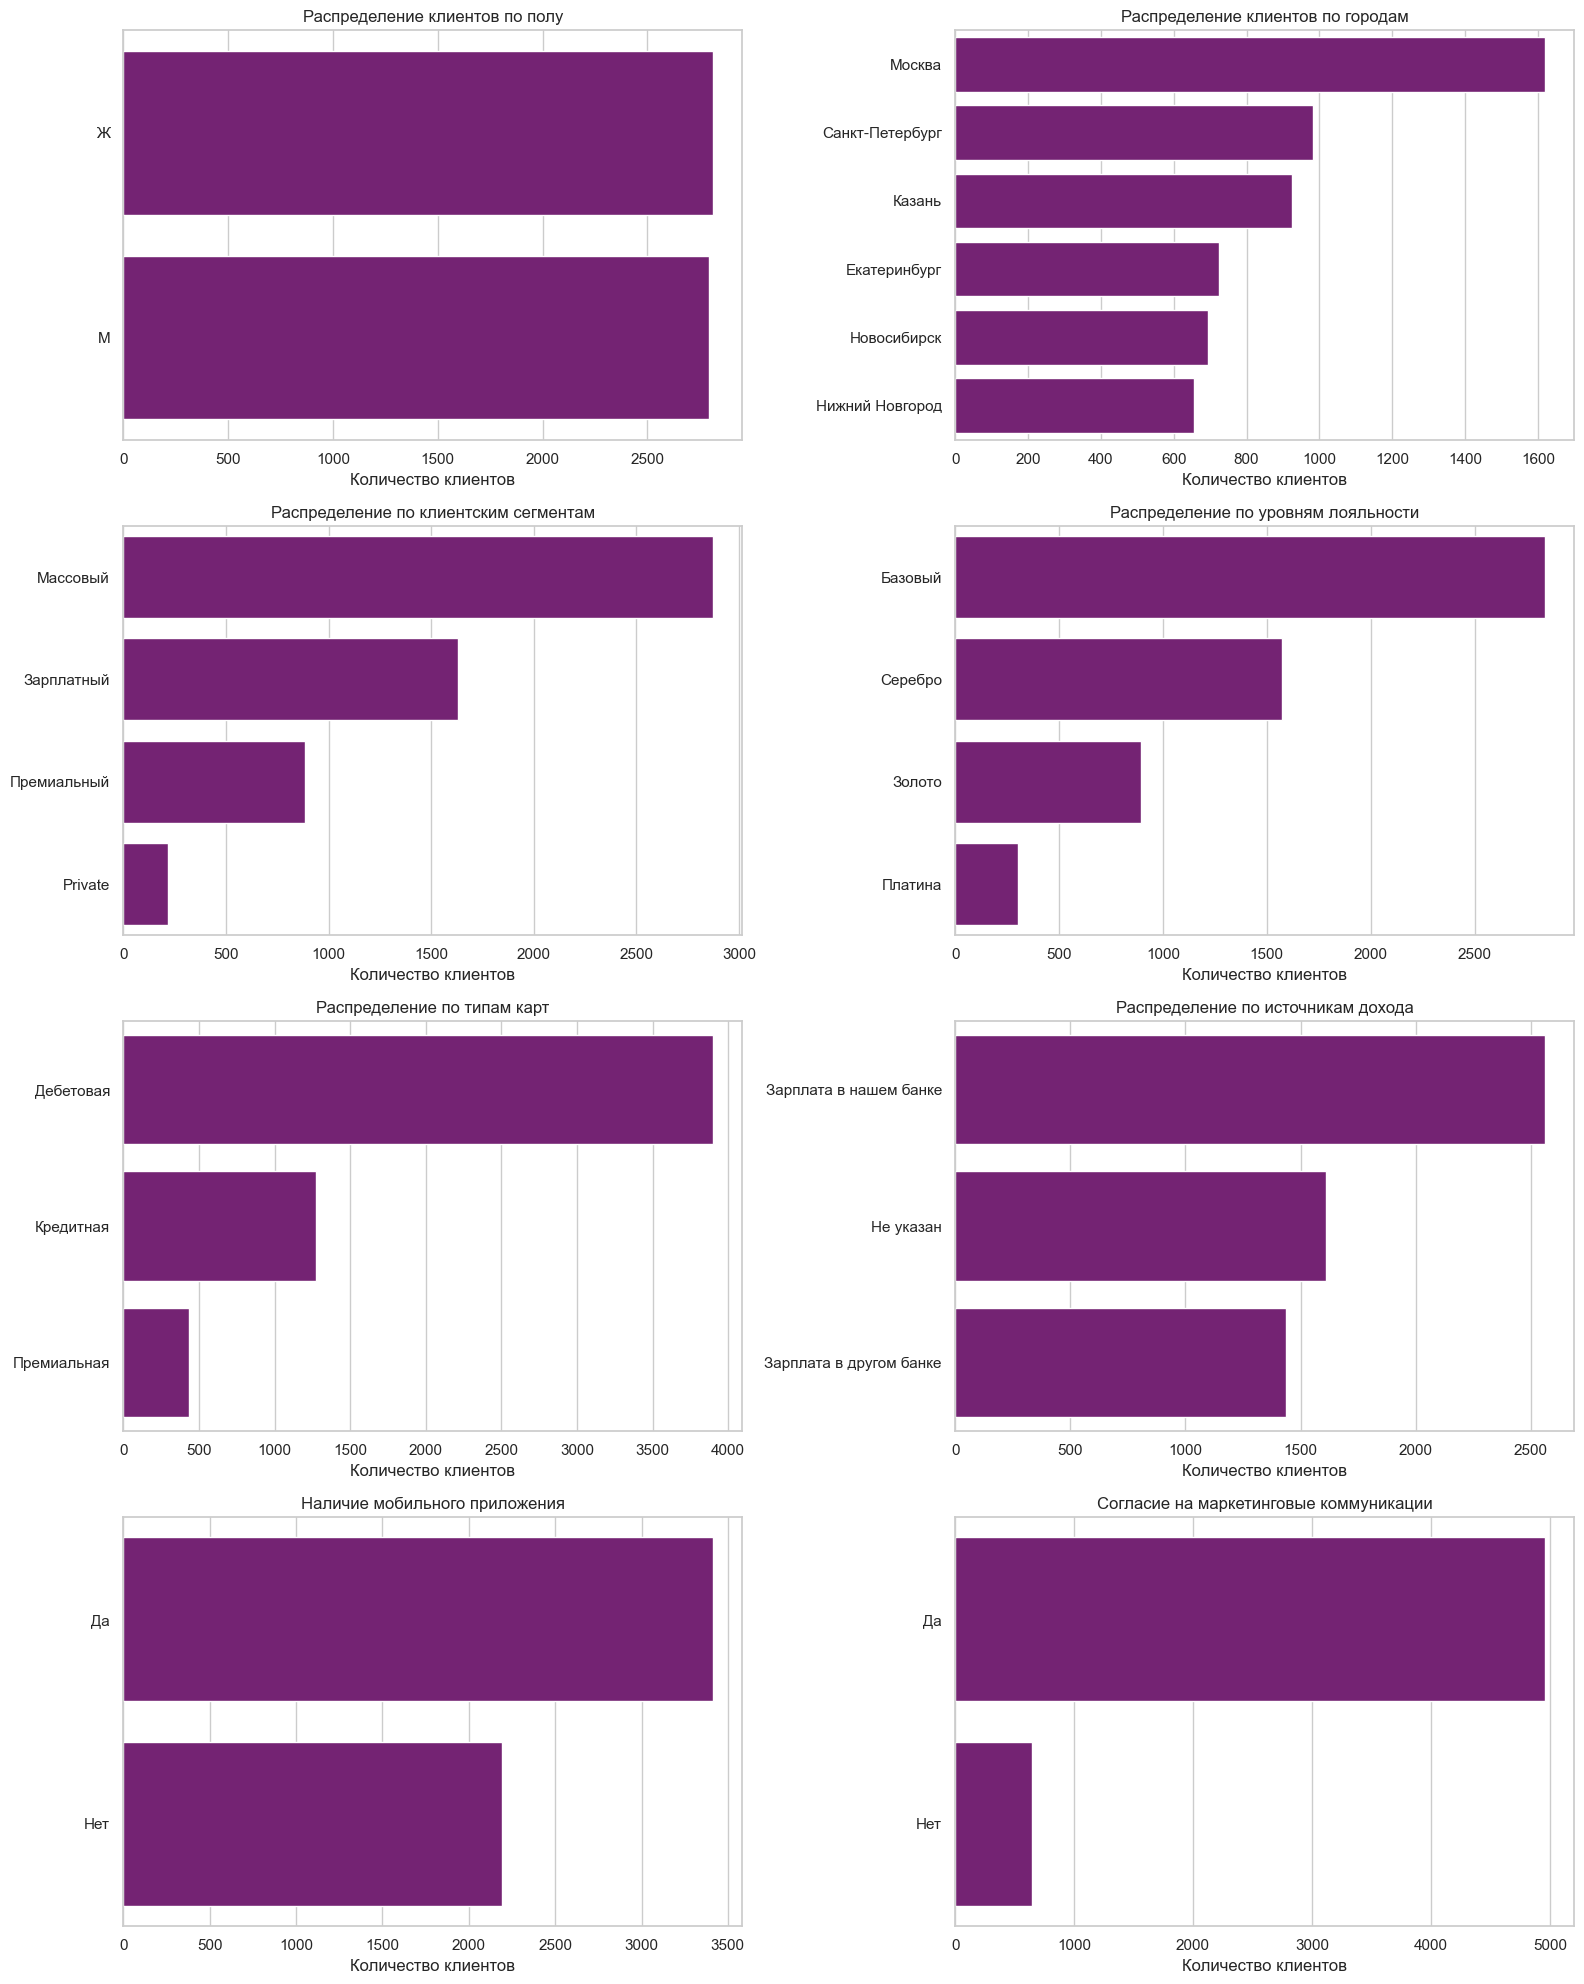

In [34]:
categorical_columns = [
    'gender',
    'city',
    'segment',
    'loyalty_tier',
    'card_type',
    'income_source',
    'has_mobile_app',
    'marketing_opt_in'
]

titles = {
    'gender': 'Распределение клиентов по полу',
    'city': 'Распределение клиентов по городам',
    'segment': 'Распределение по клиентским сегментам',
    'loyalty_tier': 'Распределение по уровням лояльности',
    'card_type': 'Распределение по типам карт',
    'income_source': 'Распределение по источникам дохода',
    'has_mobile_app': 'Наличие мобильного приложения',
    'marketing_opt_in': 'Согласие на маркетинговые коммуникации'
}
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(categorical_columns):

    order = clients[col].value_counts().index

    sns.countplot(
        data=clients,
        y=col,
        order=order,
        ax=axes[i],
        color=sns.color_palette("BuPu")[5]
    )

    axes[i].set_title(titles[col], fontsize=12)
    axes[i].set_xlabel('Количество клиентов')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

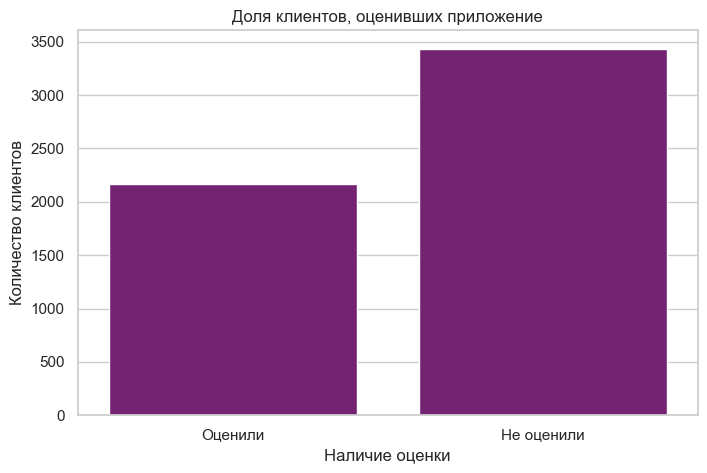

In [35]:
satisfaction_status = clients['satisfaction_score'].apply(
    lambda x: 'Оценили' if x != 'Unknown' else 'Не оценили'
)

plt.figure(figsize=(8, 5))
sns.countplot(
    x=satisfaction_status,
    order=['Оценили', 'Не оценили'],
    color=sns.color_palette("BuPu")[5]
)
plt.title('Доля клиентов, оценивших приложение')
plt.xlabel('Наличие оценки')
plt.ylabel('Количество клиентов')
plt.show()

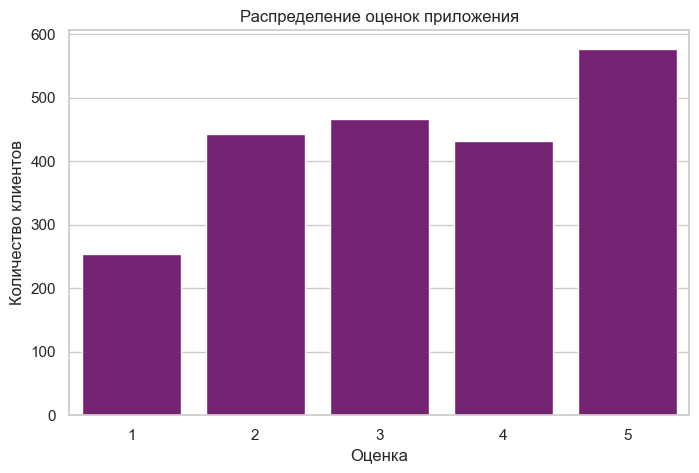

In [36]:
rated_clients = clients[
    clients['satisfaction_score'] != 'unknown'
].copy()
plt.figure(figsize=(8, 5))
sns.countplot(
    data=rated_clients,
    x='satisfaction_score',
    order=['1', '2', '3', '4', '5'],
    color=sns.color_palette("BuPu")[5]
)
plt.title('Распределение оценок приложения')
plt.xlabel('Оценка')
plt.ylabel('Количество клиентов')
plt.show()

In [37]:
categorical_columns = [
    'gender',
    'city',
    'segment',
    'loyalty_tier',
    'card_type',
    'income_source',
    'has_mobile_app',
    'marketing_opt_in'
]

for col in categorical_columns:
    print(f'\nРаспределение признака: {col}')
    freq_table = pd.DataFrame({
        'Количество': clients[col].value_counts(dropna=False),
        'Доля, %': clients[col].value_counts(
            normalize=True,
            dropna=False
        ) * 100
    })

    display(freq_table.round(2))


Распределение признака: gender


,Количество,"Доля, %"
gender,,
Ж,2811,50.16
М,2793,49.84



Распределение признака: city


,Количество,"Доля, %"
city,,
Москва,1618,28.87
Санкт-Петербург,983,17.54
Казань,926,16.52
Екатеринбург,725,12.94
Новосибирск,695,12.4
Нижний Новгород,657,11.72



Распределение признака: segment


,Количество,"Доля, %"
segment,,
Массовый,2872,51.25
Зарплатный,1630,29.09
Премиальный,886,15.81
Private,216,3.85


... (6 outputs left out)


Распределение признака: has_mobile_app


,Количество,"Доля, %"
has_mobile_app,,
Да,3412,60.89
Нет,2192,39.11



Распределение признака: marketing_opt_in


,Количество,"Доля, %"
marketing_opt_in,,
Да,4955,88.42
Нет,649,11.58


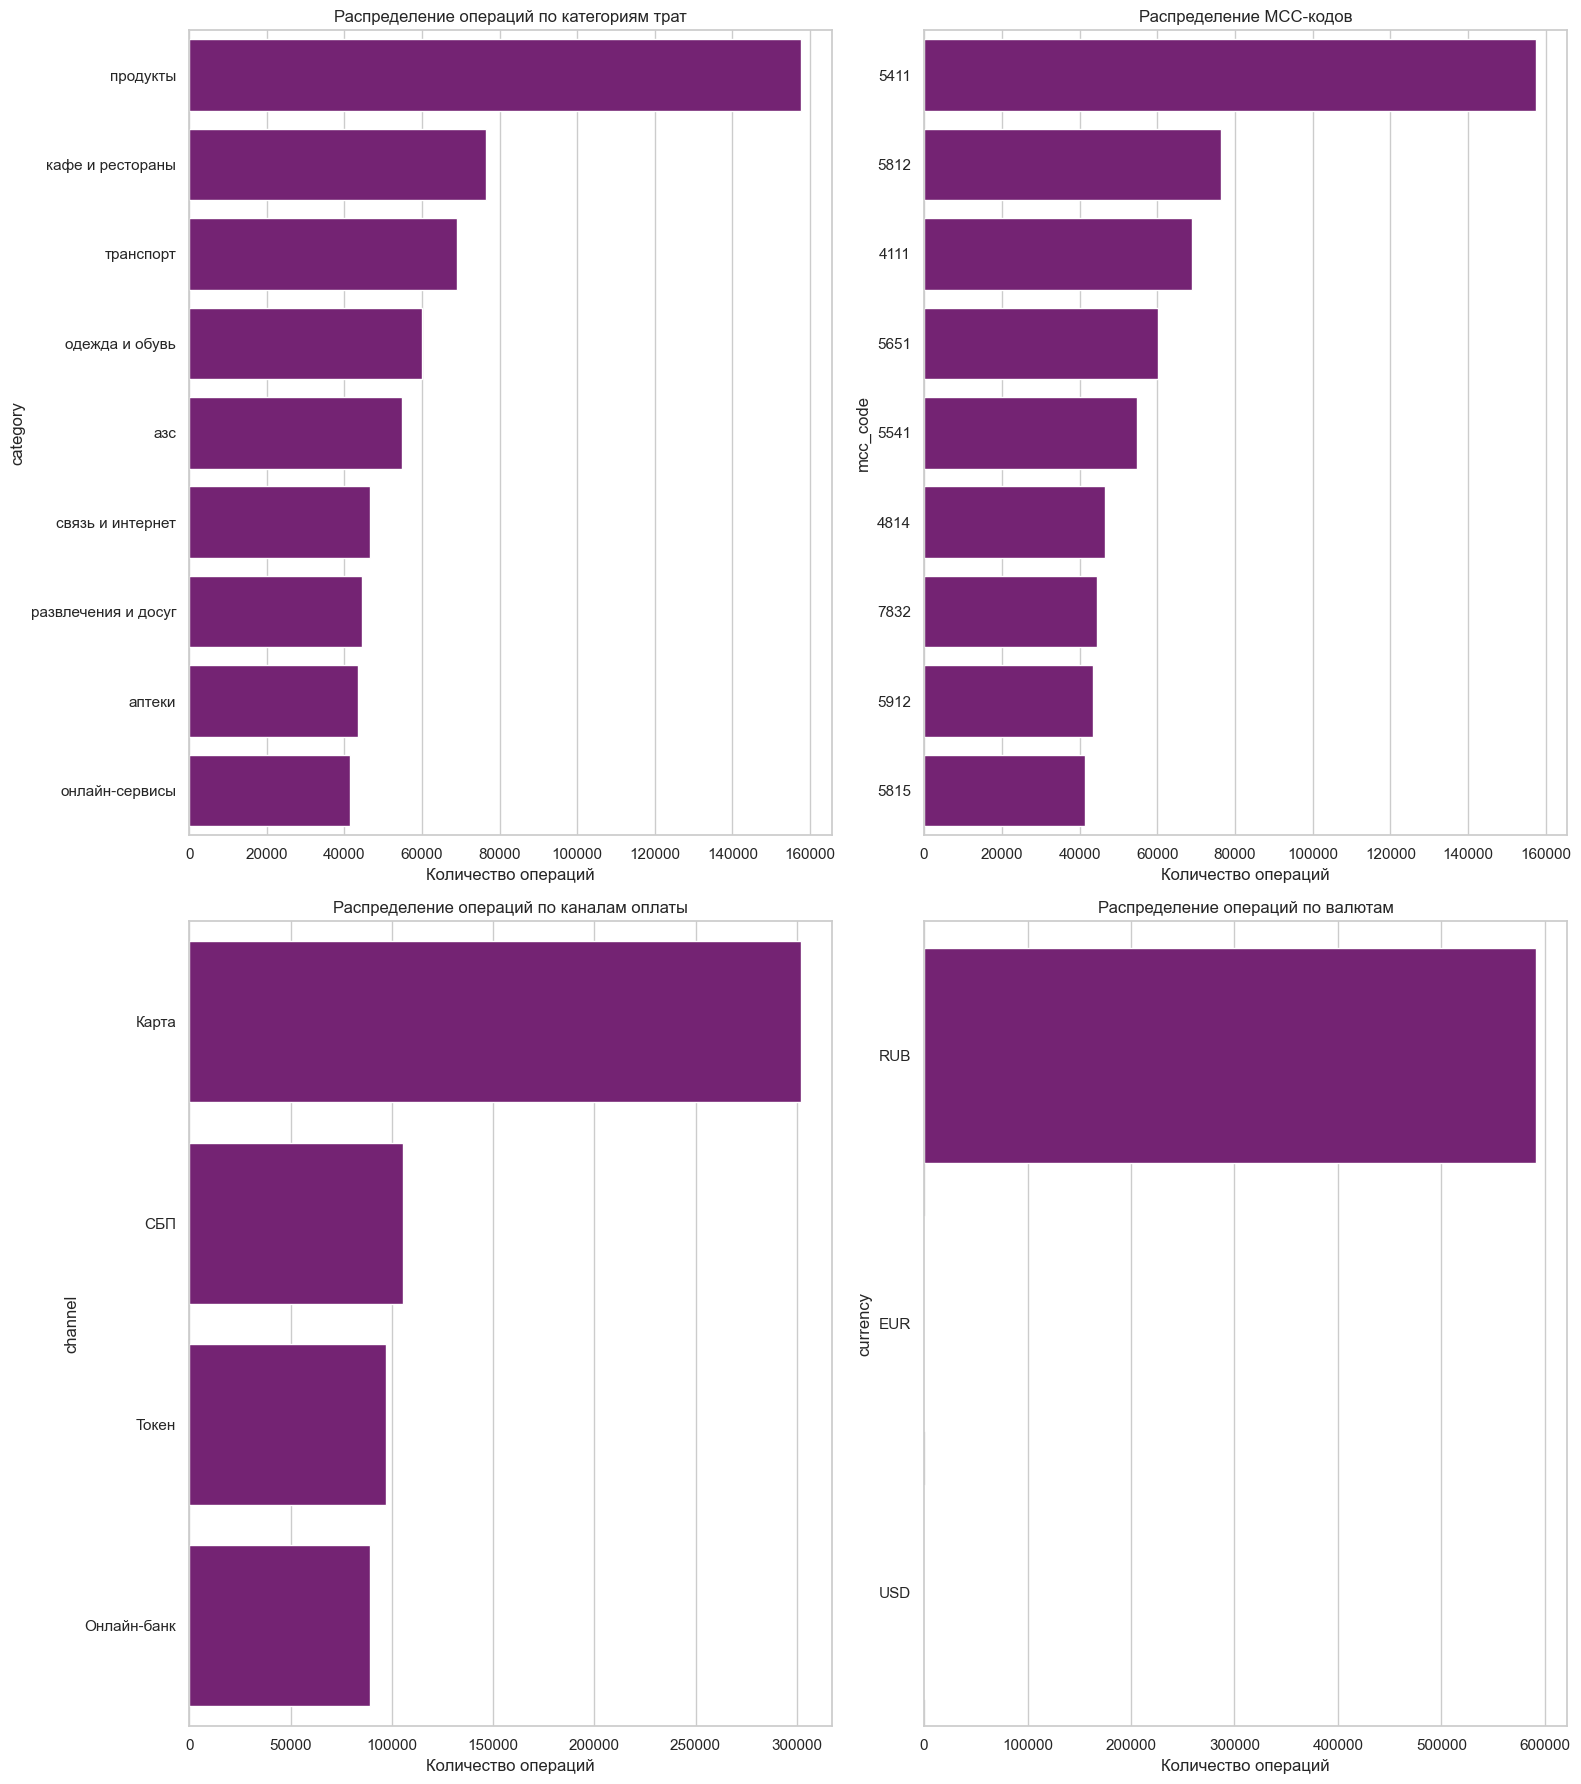

In [38]:
categorical_columns = [
    'category',
    'mcc_code',
    'channel',
    'currency'
]

titles = {
    'category': 'Распределение операций по категориям трат',
    'mcc_code': 'Распределение MCC-кодов',
    'channel': 'Распределение операций по каналам оплаты',
    'currency': 'Распределение операций по валютам'
}

fig, axes = plt.subplots(2, 2, figsize=(16, 18))
axes = axes.flatten()

for i, col in enumerate(categorical_columns):

    if col == 'mcc_code':
        order = transactions[col].value_counts().head(15).index
        data = transactions[transactions[col].isin(order)]
    else:
        order = transactions[col].value_counts().index
        data = transactions

    sns.countplot(
        data=data,
        y=col,
        order=order,
        ax=axes[i],
        color=sns.color_palette("BuPu")[5]
    )

    axes[i].set_title(titles[col], fontsize=12)
    axes[i].set_xlabel('Количество операций')
    axes[i].set_ylabel(col)


plt.tight_layout()
plt.show()

In [39]:
categorical_columns = [
    'category',
    'mcc_code',
    'channel',
    'status',
    'currency'
]
for col in categorical_columns:
    print(f'\nРаспределение признака: {col}')
    freq_table = pd.DataFrame({
        'Количество': transactions[col].value_counts(dropna=False),
        'Доля, %': transactions[col].value_counts(normalize=True, dropna=False) * 100
    })

    display(freq_table.round(2))


Распределение признака: category


,Количество,"Доля, %"
category,,
продукты,157791,26.57
кафе и рестораны,76456,12.87
транспорт,68944,11.61
одежда и обувь,60079,10.12
азс,54801,9.23
связь и интернет,46582,7.84
развлечения и досуг,44501,7.49
аптеки,43407,7.31
онлайн-сервисы,41366,6.96



Распределение признака: mcc_code


,Количество,"Доля, %"
mcc_code,,
5411,157487,26.52
5812,76442,12.87
4111,68942,11.61
5651,60099,10.12
5541,54842,9.23
4814,46626,7.85
7832,44564,7.5
5912,43458,7.32
5815,41467,6.98



Распределение признака: channel


,Количество,"Доля, %"
channel,,
Карта,302284,50.90
СБП,105288,17.73
Токен,97315,16.39
Онлайн-банк,89040,14.99



Распределение признака: status


,Количество,"Доля, %"
status,,
успешно,593927,100.0
возврат,0,0.0
отклонено,0,0.0



Распределение признака: currency


,Количество,"Доля, %"
currency,,
RUB,591596,99.61
EUR,1168,0.2
USD,1163,0.2


### 5.3. Динамика по месяцам

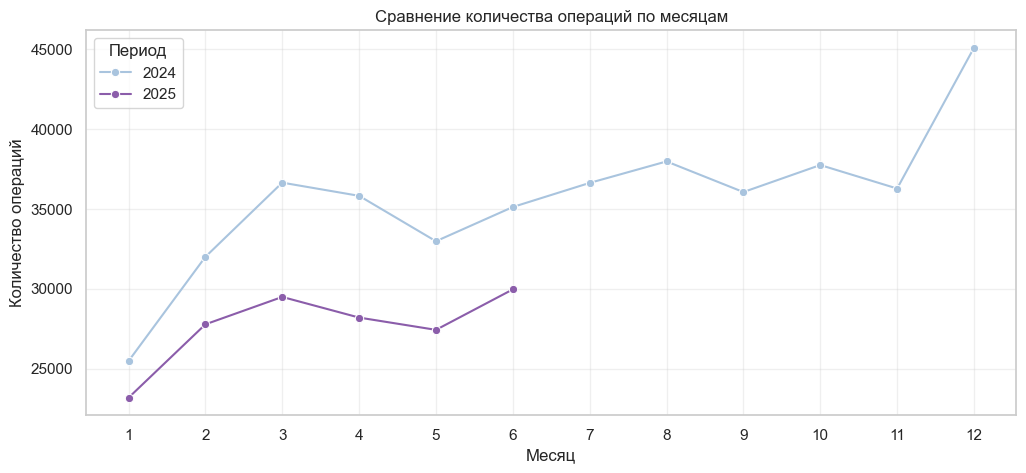

In [40]:
monthly_2024 = (
    transactions[transactions['txn_datetime'].dt.year == 2024]
    .groupby(transactions[transactions['txn_datetime'].dt.year == 2024]['txn_datetime'].dt.month)
    .size()
    .reindex(range(1, 13), fill_value=0)
    .reset_index(name='Количество операций')
)

monthly_2024['Период'] = '2024'

monthly_2025 = (
    transactions[transactions['txn_datetime'].between('2025-01-01', '2025-06-30')]
    .groupby(transactions[transactions['txn_datetime'].between('2025-01-01', '2025-06-30')]['txn_datetime'].dt.month)
    .size()
    .reindex(range(1, 7), fill_value=0)
    .reset_index(name='Количество операций')
)

monthly_2025['Период'] = '2025'

monthly = pd.concat([monthly_2024, monthly_2025])
monthly.columns = ['Месяц', 'Количество операций', 'Период']

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly,
    x='Месяц',
    y='Количество операций',
    hue='Период',
    marker='o',
    palette='BuPu'
)

plt.title('Сравнение количества операций по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество операций')
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend(title='Период')
plt.show()

In [41]:
transactions_card = transactions[((transactions['channel']=='Карта') | (transactions['channel']=='Токен'))]

In [42]:
df_2024 = transactions_card[
    (transactions_card['txn_datetime'] >= '2024-01-01') &
    (transactions_card['txn_datetime'] < '2024-07-01')
]
df_2025 = transactions_card[
    (transactions_card['txn_datetime'] >= '2025-01-01') &
    (transactions_card['txn_datetime'] < '2025-07-01')
]

count_2024 = len(df_2024)
count_2025 = len(df_2025)

result = pd.DataFrame({
    'Январь–июнь 2024': [count_2024, count_2024 / 6],
    'Январь–июнь 2025': [count_2025, count_2025 / 6]
}, index=[
    'Общее количество операций',
    'Среднее количество операций в месяц'
])

result['Изменение, %'] = (
    (result['Январь–июнь 2025'] / result['Январь–июнь 2024'] - 1) * 100
).round(2)

result

,Январь–июнь 2024,Январь–июнь 2025,"Изменение, %"
Общее количество операций,131919.0,114634.000000,-13.1
Среднее количество операций в месяц,21986.5,19105.666667,-13.1


### 5.4. Разрезы и связи между признаками

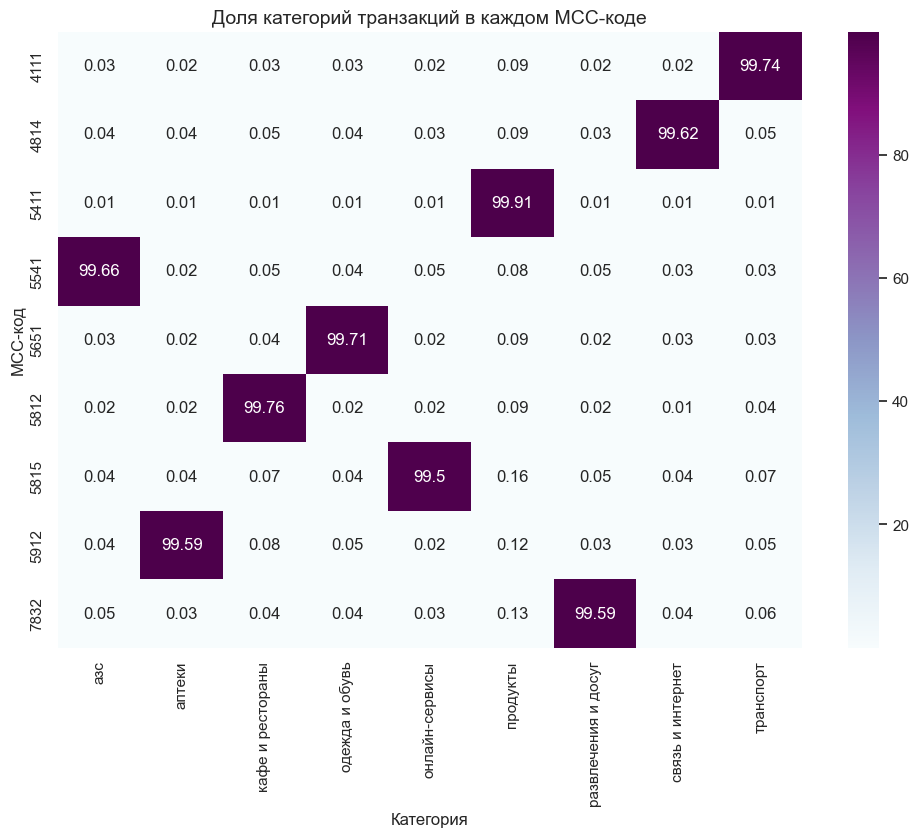

In [43]:
heatmap_data = (pd.crosstab(transactions["mcc_code"], transactions["category"], normalize='index') * 100).round(2)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, fmt="g", cmap="BuPu")

plt.title("Доля категорий транзакций в каждом MCC-коде", fontsize=14)
plt.xlabel("Категория")
plt.ylabel("MCC-код")
plt.show()

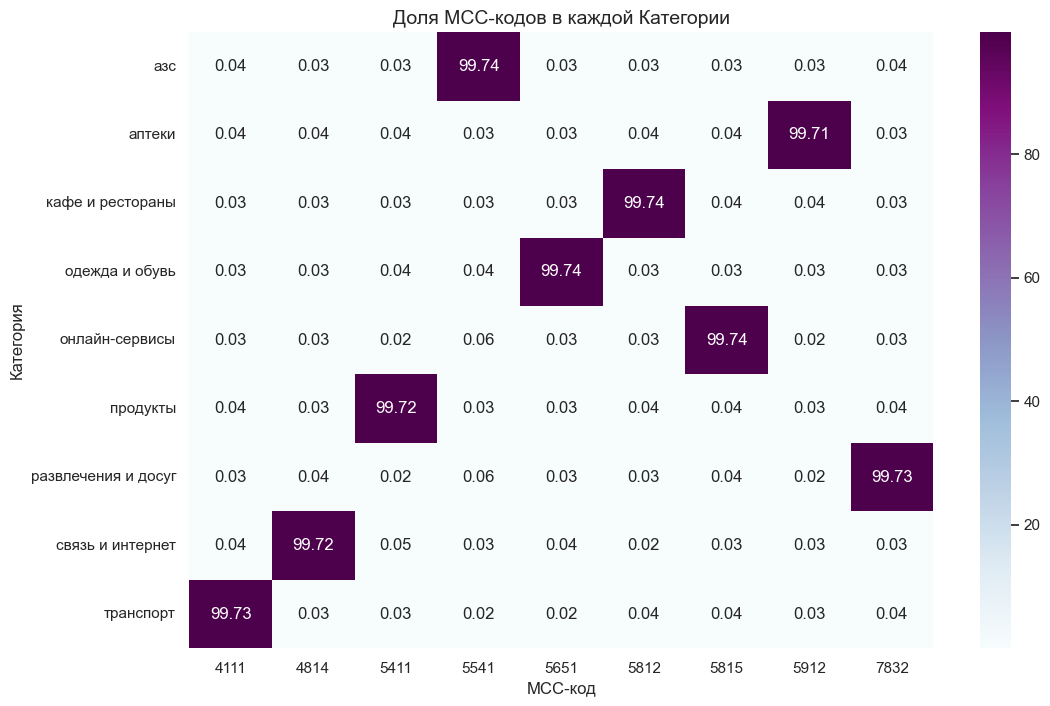

In [44]:
heatmap_data = (pd.crosstab(transactions["category"], transactions["mcc_code"], normalize='index') * 100).round(2)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, fmt="g", cmap="BuPu")

plt.title("Доля MCC-кодов в каждой Категории", fontsize=14)
plt.xlabel("MCC-код")
plt.ylabel("Категория")
plt.show()

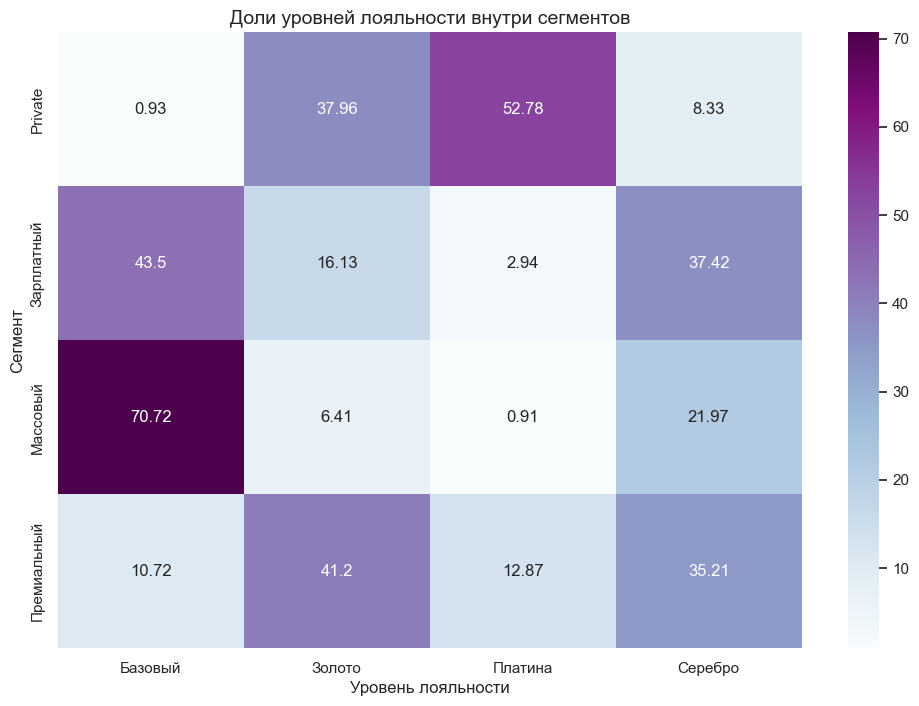

In [45]:
heatmap_data = (pd.crosstab(clients["segment"], clients["loyalty_tier"], normalize='index') * 100).round(2)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, fmt="g", cmap="BuPu")

plt.title("Доли уровней лояльности внутри сегментов", fontsize=14)
plt.xlabel("Уровень лояльности")
plt.ylabel("Сегмент")
plt.show()

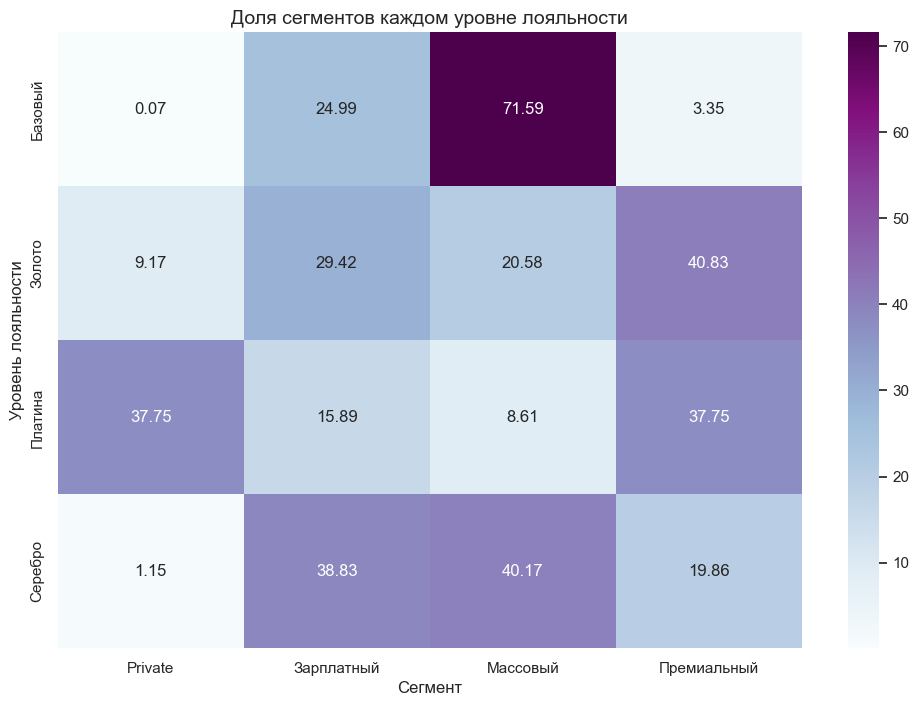

In [46]:
heatmap_data = (pd.crosstab(clients["loyalty_tier"], clients["segment"], normalize='index') * 100).round(2)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, annot=True, fmt="g", cmap="BuPu")

plt.title("Доля сегментов каждом уровне лояльности", fontsize=14)
plt.xlabel("Сегмент")
plt.ylabel("Уровень лояльности")
plt.show()

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

### За активность будем принимать количество транзакций через карту, токен, которые прошли успешно

### При сравнении будем использовать период январь-июнь 2024 и январь-июнь 2025, так как наблюдается сезонность в тратах, которая может исказить выводы

### Однако эта метрика не увидит снижение денежных оборотов по транзакциям, снижение среднего чека, переход на другие способы оплаты

### Вычислять будем на всех клиентах, при делении в группы отфильтруем только тех, кто дал согласие на маркетинговую коммуникацию

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

## Первая группа клиенты у которых не было установлено приложение и активность в первой половине 2025 снизилась на 30% относительно количества транзакций за первую половину 2024. И у которых есть разрешение на маркетинговую коммуникацию. Количество клиентов в группе 641

In [47]:
df_selected = (
    df_clean[
        (df_clean['txn_datetime'].dt.year.isin([2024, 2025])) &
        (df_clean['txn_datetime'].dt.month.between(1, 6))
    ]
    .groupby(['client_id', df_clean['txn_datetime'].dt.year])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

df_selected = df_selected[
    df_selected[2025] < df_selected[2024]*0.7
]

df_selected = df_selected.merge(
    df_clean[['client_id', 'has_mobile_app', 'marketing_opt_in']]
    .drop_duplicates('client_id'),
    on='client_id',
    how='left'
)
pril = df_selected[
    (df_selected['has_mobile_app'] == 'Нет') &
    (df_selected['marketing_opt_in'] == 'Да')
]

len(pril)

796

## Вторая группа клиенты у которых тип карты был кредитный и активность так же уменьшилась. И у которых есть разрешение на маркетинговую коммуникацию. Количество клиентов в группе 603

In [48]:
df_selected = (
    df_clean[
        (df_clean['txn_datetime'].dt.year.isin([2024, 2025])) &
        (df_clean['txn_datetime'].dt.month.between(1, 6))
    ]
    .groupby(['client_id', df_clean['txn_datetime'].dt.year])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

df_selected = df_selected[
    df_selected[2025] < df_selected[2024]
]

df_selected = df_selected.merge(
    df_clean[['client_id', 'card_type', 'marketing_opt_in']]
    .drop_duplicates('client_id'),
    on='client_id',
    how='left'
)
kred = df_selected[
    (df_selected['card_type'] == 'Кредитная') &
    (df_selected['marketing_opt_in'] == 'Да')
]

len(kred)

603

## Третья группа клиенты у которых большигство траь приходилось на группу продукты и активность в первой половине 2025 снизилась на 36% относительно количества транзакций за первую половину 2024. И у которых есть разрешение на маркетинговую коммуникацию. Количество клиентов в группе 519

In [49]:

main_cat = (
    df_clean[
        (df_clean['txn_datetime'].dt.year == 2024) &
        (df_clean['txn_datetime'].dt.month.between(1, 6))
    ]
    .groupby(['client_id', 'category']).size()
    .reset_index(name='cnt')
    .sort_values('cnt', ascending=False)
    .drop_duplicates('client_id')
    .query("category == 'продукты'")['client_id']
)
df_products = (
    df_clean[
        df_clean['client_id'].isin(main_cat) &
        (df_clean['category'] == 'продукты') &
        (df_clean['txn_datetime'].dt.year.isin([2024, 2025])) &
        (df_clean['txn_datetime'].dt.month.between(1, 6))
    ]
    .groupby(['client_id', df_clean['txn_datetime'].dt.year])
    .size()
    .unstack(fill_value=0)
)
df_selected = df_products[
    df_products[2025] < df_products[2024] * 0.64
].reset_index()
df_selected = df_selected.merge(
    df_clean[['client_id', 'marketing_opt_in']].drop_duplicates('client_id'),
    on='client_id',
    how='left'
)
prod = df_selected[df_selected['marketing_opt_in'] == 'Да']
len(prod)

1296

## Четвертая группа клиенты у проживающие в Казани, имеющий сегмент Массовый, и их активность так же уменьшилась. И у которых есть разрешение на маркетинговую коммуникацию. Количество клиентов в группе 237

In [50]:
df_activity = (
    df_clean[
        (df_clean['txn_datetime'].dt.year.isin([2024, 2025])) &
        (df_clean['txn_datetime'].dt.month.between(1, 6))
    ]
    .groupby(['client_id', df_clean['txn_datetime'].dt.year])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)
df_activity = df_activity[df_activity[2025] < df_activity[2024]]
df_selected = df_activity.merge(
    df_clean[['client_id', 'segment', 'city', 'marketing_opt_in']].drop_duplicates('client_id'),
    on='client_id',
    how='left'
)
kazan = df_selected[
    (df_selected['segment'] == 'Массовый') &
    (df_selected['city'] == 'Казань')&
    (df_selected['marketing_opt_in'] == 'Да')
]
len(kazan)

467

In [51]:
columns_to_combine = [kazan.iloc[:, 0], prod.iloc[:, 0], pril.iloc[:, 0],kred.iloc[:, 0]]
campaign = pd.concat(
    columns_to_combine, 
    keys=['Казань', 'Категория продукты', 'Нет приложения','Кредитные карты'] # Имена для второй колонки
)
campaign = campaign.reset_index(level=0)
campaign.columns = ["group","client_id"]
priority = {
    'Кредитные карты': 4,
    'Нет приложения': 3,
    'Казань': 2,
    'Категория продукты': 1,
}

campaign = (campaign.assign(_priority=campaign['group'].map(priority))
        .sort_values('_priority', ascending=False)
        .drop_duplicates(subset="client_id", keep='first')
        .drop(columns='_priority'))

In [52]:
campaign

,group,client_id
3054,Кредитные карты,C005992
3013,Кредитные карты,C005913
3018,Кредитные карты,C005931
2940,Кредитные карты,C005770
2942,Кредитные карты,C005773
...,...,...
1423,Категория продукты,C005851
1424,Категория продукты,C005854
1426,Категория продукты,C005856
1428,Категория продукты,C005863


In [53]:
campaign['group'].value_counts()

group
Нет приложения        641
Кредитные карты       603
Категория продукты    519
Казань                237
Name: count, dtype: int64

In [54]:
clean = pd.merge(df_clean, campaign, on='client_id', how='left')

### Были перечечения по категориям, так как клиент может относится только к одной категории, то был сделан приоритет категорий 'Кредитные карты' ->'Нет приложения'->'Казань'->'Категория продукты'

### 7.1. Кого в кампанию не берём и почему

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

#### Гипотеза, что среди людей, которые поставили низкую оценку качества, будет большее проседание по активности. Из всех людей у которых уменьшилась активность только 12% людей ставили оценку качества 1 или 2, 25% ставили 3-5, остальные не оценивали

#### Гипотеза, что в каком-то из сегментов, типов карты или источнике дохода больше чем в остальных снизилась активность. На практике соотношения в категориях осталось на прежнем уровне

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [56]:
clean.to_parquet("clean_data.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")